<a href="https://colab.research.google.com/github/danielaceves5162/Tareas_TS_Aceves_Daniel/blob/main/HW2_Aceves_Daniel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TAREA 2: muestreo con reemplazo Y HETEROGENEIDAD

Aceves Maya Christopher Daniel

Temas selectos

fecha de entrega 10 de septiembre de 2026

DR. MOISES VELASCO LOZANO

1. Introducción

Para esta tarea vamos a tener como objetivo analizar el comportamiento estadístico de una muestra de datos de porosidad mediante técnicas de muestreo con reemplazo, comparando la muestra original con los resultados obtenidos a partir de múltiples muestras generadas con reemplazo.

2. Desarrollo

Como primera parte del desarrollo vamos a importar las librerías

In [ ]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
np.random.seed(15)

2.1 Desarrollo

Para la siguiente parte del código primero se determinan los parámetros de nuestra muestra original, se realiza un histograma de la muestra original, se hace un muestreo con reemplazo de 1000 muestras se calculan y se hace un histograma de las desviaciones estándar de dichas muestras con reemplazo y por último se realiza un histograma comparando ambos muestreos

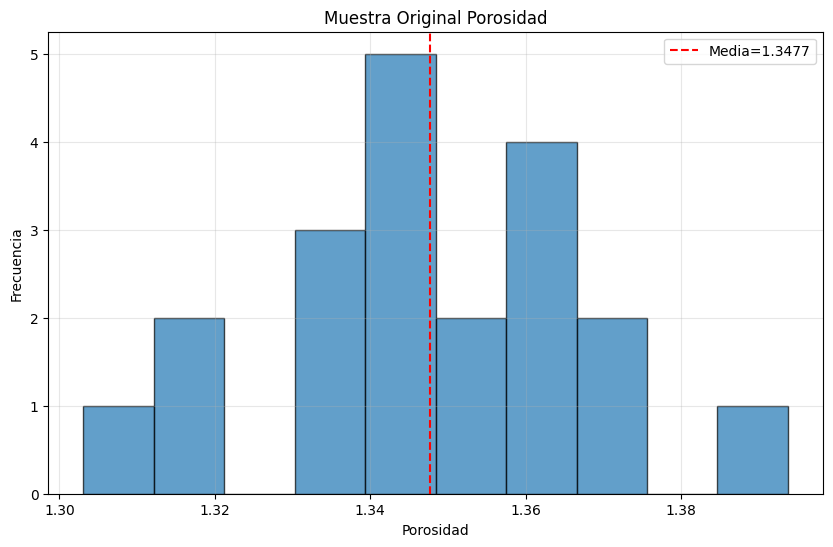

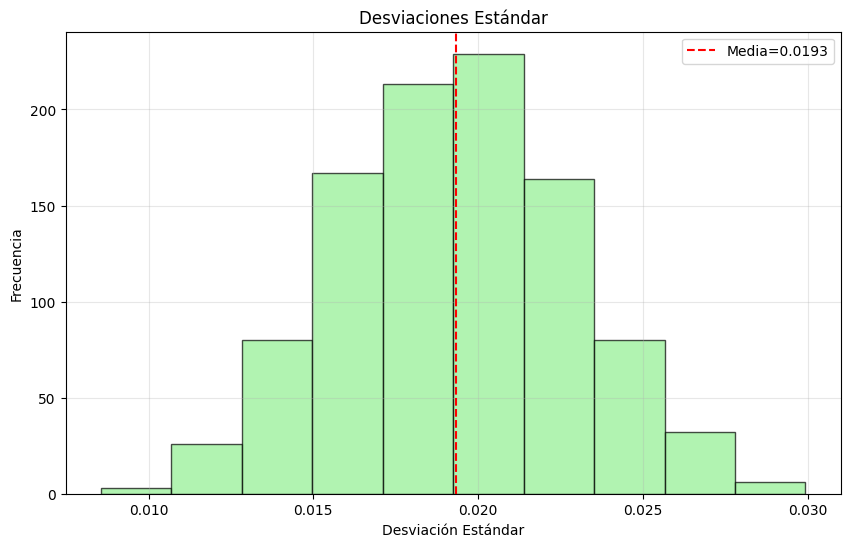

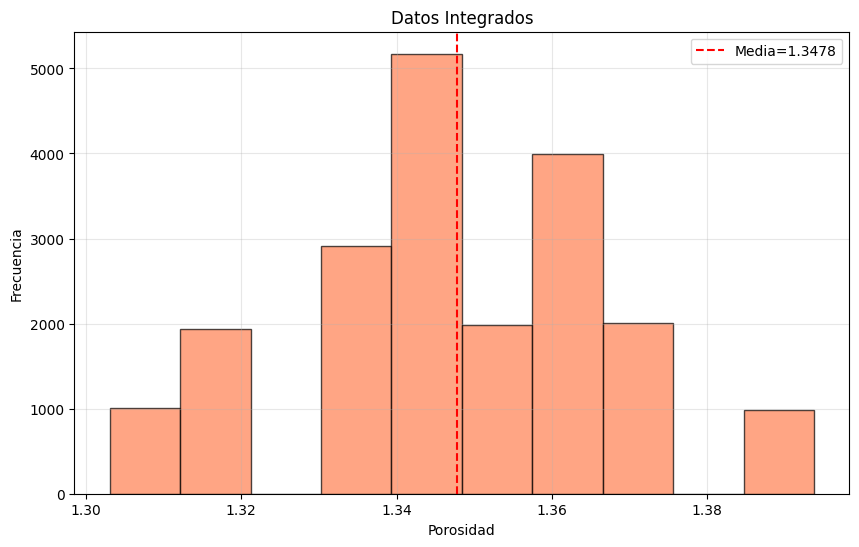

              Conjunto     n    Media      Std      P10      P50      P90
              Original    20 1.347713 0.020266 1.320788 1.345562 1.368408
muestreo con reemplazo 20000 1.347776 0.019654 1.320809 1.345656 1.368603


In [ ]:
# primera parte
np.random.seed(15)
mu, sigma, n, n_boot, size = 0.30, 0.02, 20, 1000, 20
original = np.random.lognormal(mean=mu, sigma=sigma, size=n)
media_o, std_o = np.mean(original), np.std(original, ddof=1)

plt.figure(figsize=(10,6)); plt.hist(original, bins=10, edgecolor='black', alpha=0.7)
plt.title('Muestra Original Porosidad'); plt.xlabel('Porosidad'); plt.ylabel('Frecuencia')
plt.axvline(media_o, color='red', linestyle='dashed', label=f'Media={media_o:.4f}')
plt.grid(True, alpha=0.3); plt.legend(); plt.show()

boot = np.array([np.random.choice(original, size=size, replace=True) for _ in range(n_boot)])
stds = np.array([np.std(boot[i], ddof=1) for i in range(n_boot)])

plt.figure(figsize=(10,6)); plt.hist(stds, bins=10, edgecolor='black', color='lightgreen', alpha=0.7)
plt.title('Desviaciones Estándar'); plt.xlabel('Desviación Estándar'); plt.ylabel('Frecuencia')
plt.axvline(np.mean(stds), color='red', linestyle='dashed', label=f'Media={np.mean(stds):.4f}')
plt.grid(True, alpha=0.3); plt.legend(); plt.show()

total = boot.flatten()
media_t, std_t = np.mean(total), np.std(total, ddof=1)

plt.figure(figsize=(10,6)); plt.hist(total, bins=10, edgecolor='black', color='coral', alpha=0.7)
plt.title('Datos Integrados'); plt.xlabel('Porosidad'); plt.ylabel('Frecuencia')
plt.axvline(media_t, color='red', linestyle='dashed', label=f'Media={media_t:.4f}')
plt.grid(True, alpha=0.3); plt.legend(); plt.show()

df = pd.DataFrame({
    'Conjunto': ['Original', 'muestreo con reemplazo'],
    'n': [n, len(total)],
    'Media': [media_o, media_t],
    'Std': [std_o, std_t],
    'P10': [np.percentile(original, 10), np.percentile(total, 10)],
    'P50': [np.percentile(original, 50), np.percentile(total, 50)],
    'P90': [np.percentile(original, 90), np.percentile(total, 90)]
}).round(6)
print(df.to_string(index=False))

2.2 Desarrollo

para la siguiente parte del código se genera tres conjuntos de datos de permeabilidad que sigan una distribución
lognormal. Considerando Para cada conjunto una media de 100 y generando 1000 valores de permeabilidad con intención de utilizar el método Dykstra–Parsons.

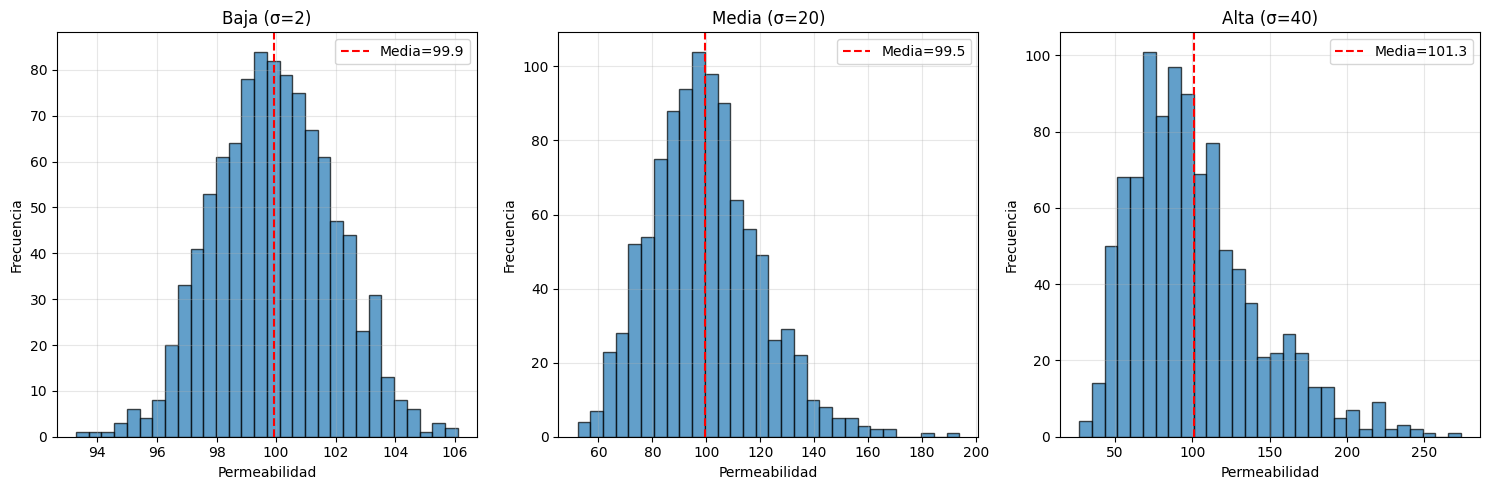

        Caso     P10     P50      P90  Índice Heterogeneidad     CV
  Baja (σ=2) 97.3370 99.9059 102.4867                 0.0515 0.0200
Media (σ=20) 74.5938 97.6019 125.9665                 0.5263 0.2004
 Alta (σ=40) 55.4836 94.0117 161.1772                 1.1243 0.3996


/tmp/ipykernel_836/337895121.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(list(datos.values()), labels=list(datos.keys()))


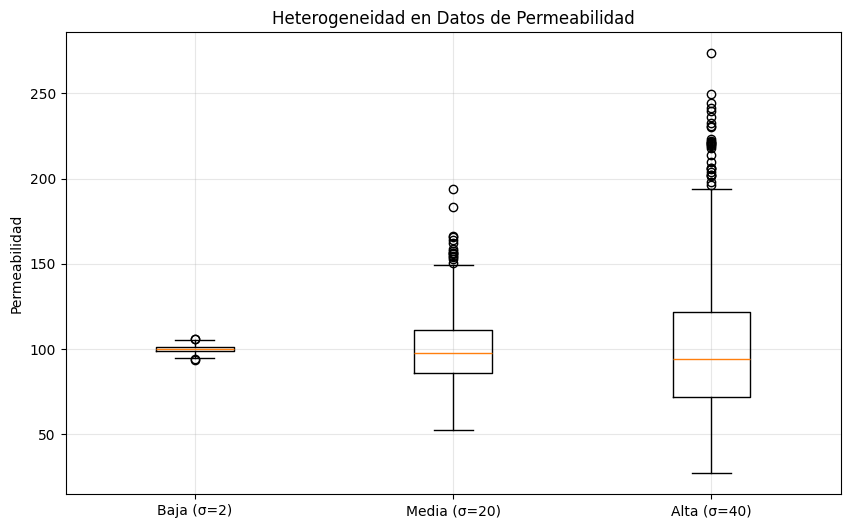

In [ ]:
# segunda parte
def lognormal_params(mean, std):
    mu = np.log(mean**2 / np.sqrt(mean**2 + std**2))
    sigma = np.sqrt(np.log(1 + std**2 / mean**2))
    return mu, sigma

media_perm, n_perm = 100, 1000
casos = {'Baja (σ=2)': 2, 'Media (σ=20)': 20, 'Alta (σ=40)': 40}

datos = {}
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for idx, (nombre, std) in enumerate(casos.items()):
    mu, sig = lognormal_params(media_perm, std)
    d = np.random.lognormal(mean=mu, sigma=sig, size=n_perm)
    datos[nombre] = d
    axes[idx].hist(d, bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_title(nombre); axes[idx].set_xlabel('Permeabilidad'); axes[idx].set_ylabel('Frecuencia')
    axes[idx].axvline(np.mean(d), color='red', linestyle='dashed', label=f'Media={np.mean(d):.1f}')
    axes[idx].grid(True, alpha=0.3); axes[idx].legend()
plt.tight_layout(); plt.show()

# Tabla de heterogeneidad
data = []
for nombre, d in datos.items():
    p10, p50, p90 = np.percentile(d, [10, 50, 90])
    data.append([nombre, p10, p50, p90, (p90-p10)/p50, np.std(d, ddof=1)/np.mean(d)])

df_het = pd.DataFrame(data, columns=['Caso', 'P10', 'P50', 'P90', 'Índice Heterogeneidad', 'CV']).round(4)
print(df_het.to_string(index=False))

# Boxplot comparativo
plt.figure(figsize=(10,6))
plt.boxplot(list(datos.values()), labels=list(datos.keys()))
plt.title('Heterogeneidad en Datos de Permeabilidad'); plt.ylabel('Permeabilidad')
plt.grid(True, alpha=0.3); plt.show()

3. Conclusión

Durante la primera parte de la tarea analizamos los datos de nuestro muestreo original y nuestro muestreo con reemplazo y podemos observar que la diferencia de los datos son prácticamente nulas y en la segunda parte si se puede apreciar un cambio en la desviación estándar pero la media se mantiene prácticamente igual en los 3 casos.

4. Referencias

MoisesVL. (s/f). Special topics/notebooks/GUIA_PYTHON_LQX_V1.Lyx~ at main · Moises13r/PetroleumEng.